# Лабораторная работа №1: регрессия

**Задача:** по физико-химическим характеристикам вина предсказать его качество `quality` (экспертная оценка от 0 до 10).

**Датасет:** [Wine Quality (UCI)](https://archive.ics.uci.edu/dataset/186/wine+quality) — красные и белые вина «Vinho Verde».

**Основная метрика:** RMSE (цель — RMSE < 0.70), дополнительная — MAE.

План работы:
1. Знакомство с данными (EDA) и выводы.
2. Разбиение на train / test.
3. Baseline — константное предсказание.
4. Метрики RMSE и MAE.
5. Модели: Linear Regression, Random Forest, Gradient Boosting.
6. Честное сравнение моделей.
7. Feature importance.
8. Анализ ошибок лучшей модели.

In [1]:
import warnings
warnings.simplefilter("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import root_mean_squared_error, mean_absolute_error

%matplotlib inline
sns.set(style="darkgrid")
pd.set_option("display.precision", 3)

RANDOM_STATE = 42

# 1. Знакомство с данными

Датасет состоит из двух файлов: красные (1599 шт.) и белые (4898 шт.) вина. Признаки в обоих файлах одинаковые, поэтому объединим их в одну таблицу и добавим бинарный признак `is_red` — тип вина. Так модель получит больше данных и сможет сама учесть различия между типами.

In [2]:
red = pd.read_csv("data/winequality-red.csv", sep=";")
white = pd.read_csv("data/winequality-white.csv", sep=";")
red["is_red"] = 1
white["is_red"] = 0

data = pd.concat([red, white], ignore_index=True)
print("Размер датасета:", data.shape)
data.head()

Размер датасета: (6497, 13)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,is_red
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.998,3.51,0.56,9.4,5,1
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.997,3.20,0.68,9.8,5,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.997,3.26,0.65,9.8,5,1
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.998,3.16,0.58,9.8,6,1
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.998,3.51,0.56,9.4,5,1


In [3]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         6497 non-null   float64
 1   volatile acidity      6497 non-null   float64
 2   citric acid           6497 non-null   float64
 3   residual sugar        6497 non-null   float64
 4   chlorides             6497 non-null   float64
 5   free sulfur dioxide   6497 non-null   float64
 6   total sulfur dioxide  6497 non-null   float64
 7   density               6497 non-null   float64
 8   pH                    6497 non-null   float64
 9   sulphates             6497 non-null   float64
 10  alcohol               6497 non-null   float64
 11  quality               6497 non-null   int64  
 12  is_red                6497 non-null   int64  
dtypes: float64(11), int64(2)
memory usage: 660.0 KB


In [4]:
print("Пропусков:", data.isna().sum().sum())
print("Полных дубликатов строк:", data.duplicated().sum())
data.describe().T

Пропусков: 0
Полных дубликатов строк: 1177


,count,mean,std,min,25%,50%,75%,max
fixed acidity,6497.0,7.215,1.296,3.800,6.400,7.000,7.700,15.900
volatile acidity,6497.0,0.340,0.165,0.080,0.230,0.290,0.400,1.580
citric acid,6497.0,0.319,0.145,0.000,0.250,0.310,0.390,1.660
residual sugar,6497.0,5.443,4.758,0.600,1.800,3.000,8.100,65.800
chlorides,6497.0,0.056,0.035,0.009,0.038,0.047,0.065,0.611
free sulfur dioxide,6497.0,30.525,17.749,1.000,17.000,29.000,41.000,289.000
total sulfur dioxide,6497.0,115.745,56.522,6.000,77.000,118.000,156.000,440.000
density,6497.0,0.995,0.003,0.987,0.992,0.995,0.997,1.039
pH,6497.0,3.219,0.161,2.720,3.110,3.210,3.320,4.010
sulphates,6497.0,0.531,0.149,0.220,0.430,0.510,0.600,2.000


**Выводы по структуре данных:**
- 6497 объектов, 11 числовых физико-химических признаков + `is_red`, пропусков нет — заполнять ничего не нужно.
- Признаки измерены в очень разных масштабах: `density` ≈ 0.99 с разбросом в тысячные доли, а `total sulfur dioxide` — десятки и сотни единиц. Значит, коэффициенты линейной регрессии на сырых данных нельзя сравнивать напрямую — понадобится масштабирование.
- У ряда признаков (`residual sugar`, `chlorides`, `free sulfur dioxide`, `total sulfur dioxide`) максимум в разы больше 75-го перцентиля — есть выбросы и тяжёлые правые хвосты. Для линейной модели это может быть проблемой, деревья к этому устойчивы.
- Около 1177 строк — полные дубликаты. Скорее всего, это разные бутылки/партии с одинаковыми результатами анализа и одинаковой оценкой. Мы их не удаляем (они часть исходного датасета, и скрытая тестовая выборка, вероятно, устроена так же), но помним: при случайном разбиении дубликат может попасть и в train, и в test, что немного «помогает» моделям, умеющим запоминать объекты (например, случайному лесу).

## Целевая переменная `quality`

quality
3    0.005
4    0.033
5    0.329
6    0.437
7    0.166
8    0.030
9    0.001
Name: count, dtype: float64


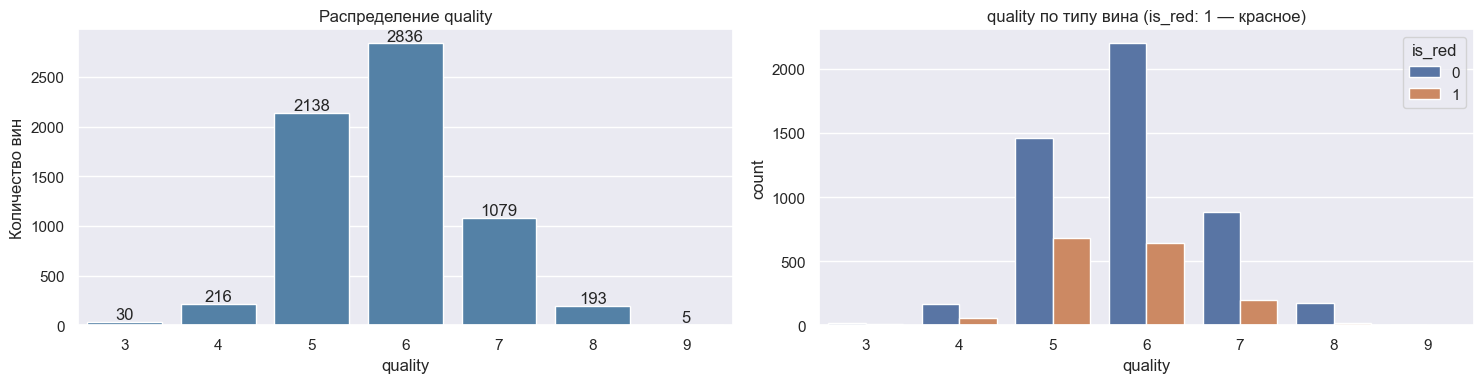

In [5]:
fig, axs = plt.subplots(figsize=(15, 4), ncols=2)

counts = data["quality"].value_counts().sort_index()
sns.barplot(x=counts.index, y=counts.values, ax=axs[0], color="steelblue")
axs[0].set_title("Распределение quality")
axs[0].set_xlabel("quality")
axs[0].set_ylabel("Количество вин")
for i, v in enumerate(counts.values):
    axs[0].text(i, v + 30, str(v), ha="center")

sns.countplot(data=data, x="quality", hue="is_red", ax=axs[1])
axs[1].set_title("quality по типу вина (is_red: 1 — красное)")
plt.tight_layout()

print((counts / len(data)).round(3))

**Выводы по целевой переменной:**
- `quality` принимает всего 7 целых значений (3–9), хотя шкала 0–10. Распределение похоже на нормальное и очень несбалансированное: оценки 5 и 6 составляют ~77% выборки, а оценок 3 и 9 — всего 30 и 5 штук.
- Следствие для моделирования: модель, минимизирующая квадратичную ошибку, будет «стягивать» предсказания к центру (5–6), а крайние значения предсказывать плохо — о них слишком мало примеров. Это стоит проверить в анализе ошибок.
- Из-за редких классов при разбиении имеет смысл использовать стратификацию по `quality`, чтобы в тест попали все уровни качества в той же пропорции.
- Задача по сути порядковая (ordinal), но мы решаем её как регрессию: предсказание 5.7 вполне осмысленно — «ближе к 6, чем к 5».

## Распределения признаков

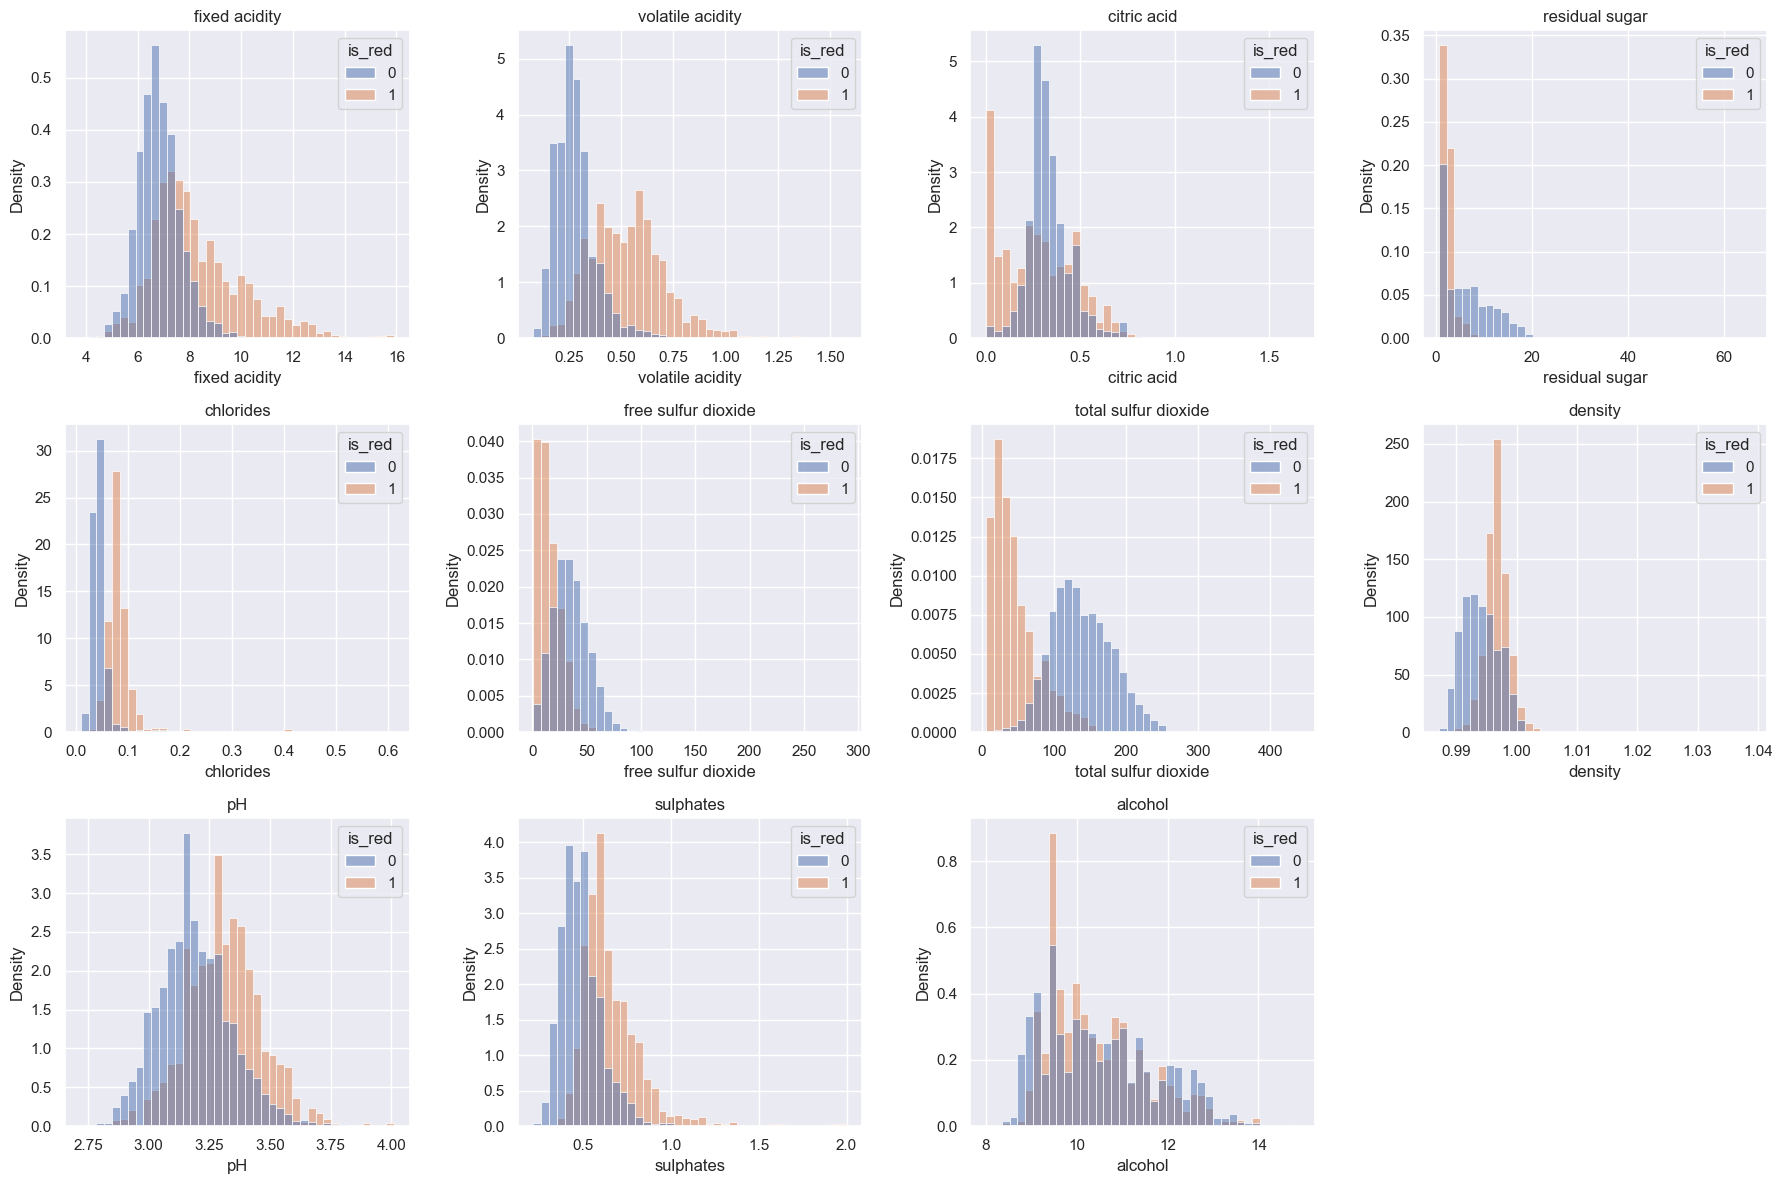

In [6]:
features = [c for c in data.columns if c != "quality"]
num_features = [c for c in features if c != "is_red"]

fig, axs = plt.subplots(figsize=(18, 12), nrows=3, ncols=4)
for ax, col in zip(axs.ravel(), num_features):
    sns.histplot(data=data, x=col, hue="is_red", bins=40, ax=ax, stat="density", common_norm=False)
    ax.set_title(col)
axs.ravel()[-1].axis("off")
plt.tight_layout()

**Выводы:**
- Красные и белые вина заметно различаются по химии: у белых значительно больше `residual sugar` и `total sulfur dioxide`, у красных — выше `volatile acidity`, `chlorides`, `fixed acidity`, `sulphates`. То есть `is_red` во многом «закодирован» в остальных признаках, и модели могут различать тип вина и без него.
- Многие распределения скошены вправо с длинными хвостами (`residual sugar`, `chlorides`, сернистые признаки). Линейная регрессия чувствительна к таким выбросам, а деревьям важен только порядок значений, поэтому для них это не проблема.

## Связь признаков с качеством

density                -0.306
volatile acidity       -0.266
chlorides              -0.201
is_red                 -0.119
fixed acidity          -0.077
total sulfur dioxide   -0.041
residual sugar         -0.037
pH                      0.020
sulphates               0.038
free sulfur dioxide     0.055
citric acid             0.086
alcohol                 0.444
Name: quality, dtype: float64

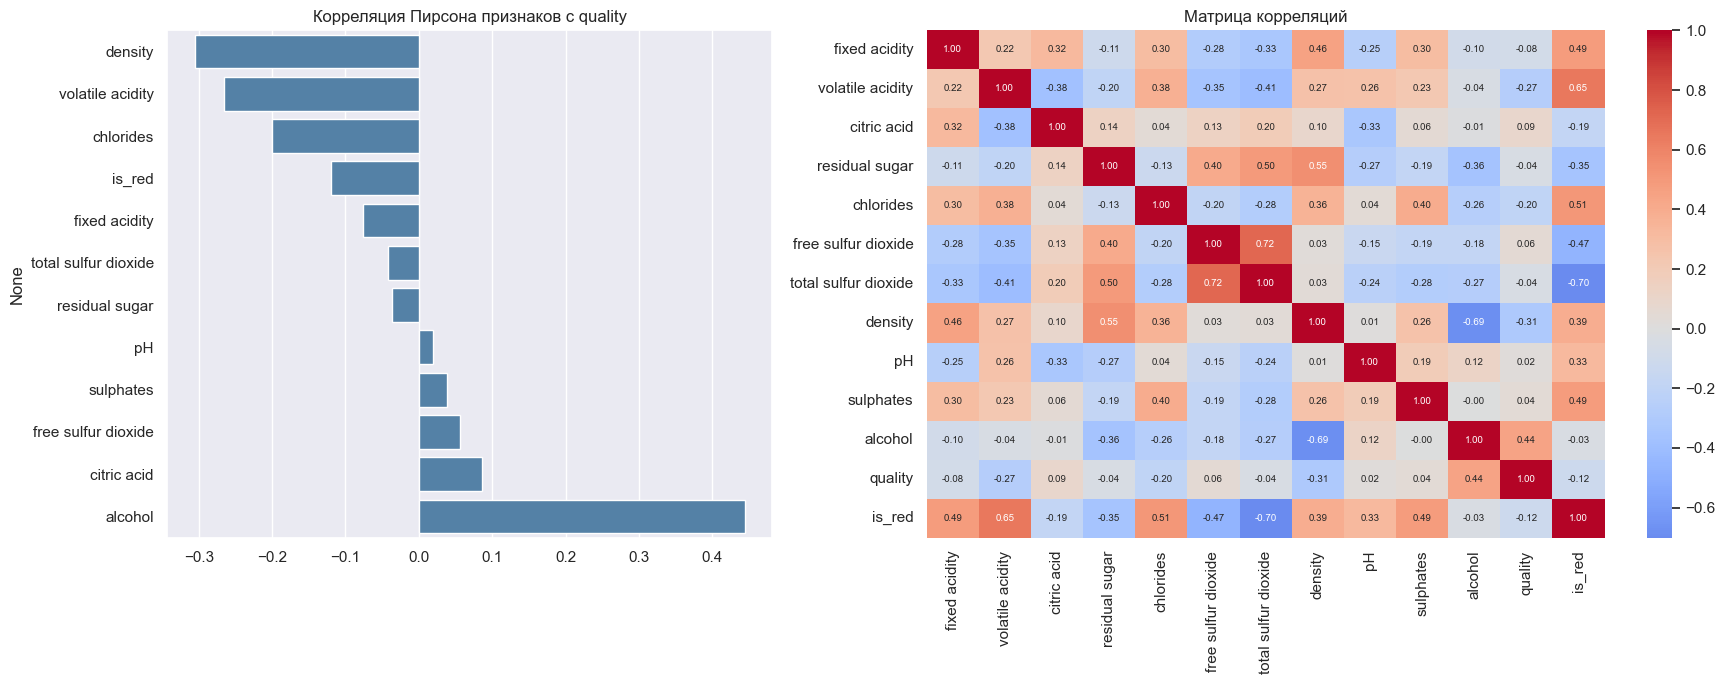

In [7]:
corr = data.corr()
quality_corr = corr["quality"].drop("quality").sort_values()

fig, axs = plt.subplots(figsize=(18, 7), ncols=2, gridspec_kw={"width_ratios": [1, 1.4]})
sns.barplot(x=quality_corr.values, y=quality_corr.index, ax=axs[0], color="steelblue")
axs[0].set_title("Корреляция Пирсона признаков с quality")
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=axs[1], annot_kws={"size": 7})
axs[1].set_title("Матрица корреляций")
plt.tight_layout()
quality_corr

,alcohol,density,volatile acidity,chlorides
quality,,,,
3,10.15,0.996,0.415,0.055
4,10.00,0.995,0.380,0.051
5,9.60,0.996,0.330,0.053
6,10.50,0.995,0.270,0.046
7,11.40,0.992,0.270,0.039
8,12.00,0.992,0.280,0.037
9,12.50,0.990,0.270,0.031


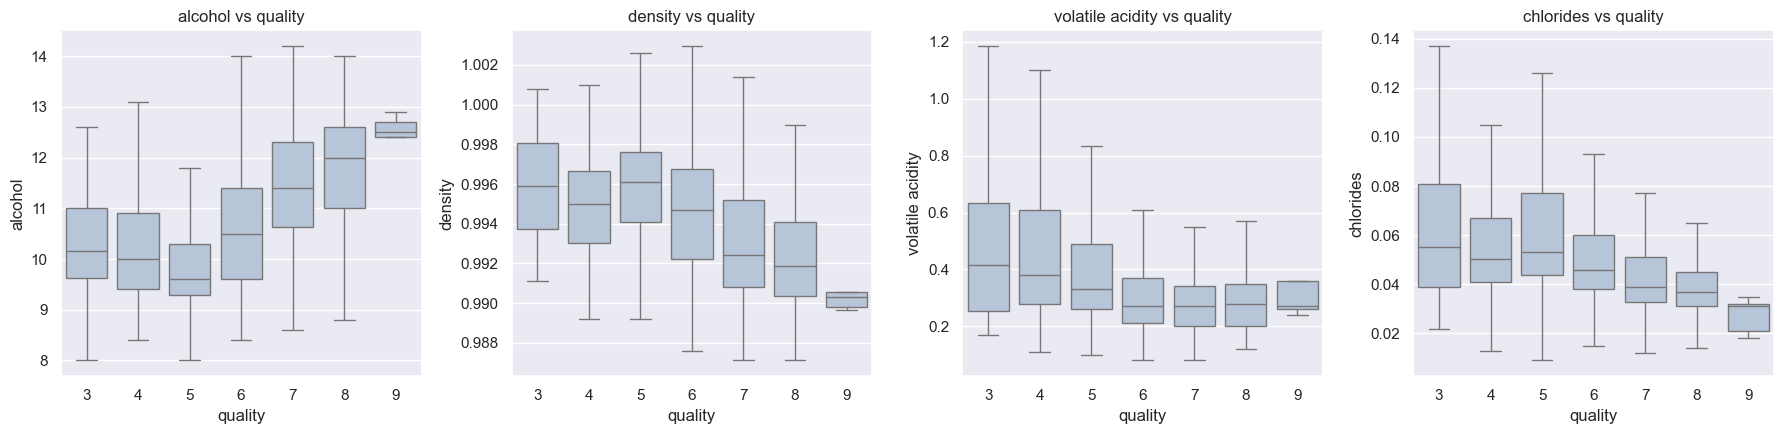

In [8]:
fig, axs = plt.subplots(figsize=(18, 4.5), ncols=4)
for ax, col in zip(axs, ["alcohol", "density", "volatile acidity", "chlorides"]):
    sns.boxplot(data=data, x="quality", y=col, ax=ax, color="lightsteelblue", showfliers=False)
    ax.set_title(f"{col} vs quality")
plt.tight_layout()

data.groupby("quality")[["alcohol", "density", "volatile acidity", "chlorides"]].median()

**Выводы по связи признаков и качества:**
- **`alcohol`** — самый сильный признак (корреляция ≈ 0.44). Медиана содержания спирта растёт от ~10% у вин с оценкой 5 до ~12% у вин с оценкой 8. Для задачи это значит, что более «крепкие» (выдержанные, из более зрелого винограда) вина эксперты оценивают выше. Признак обязательно нужно использовать, и мы ожидаем увидеть его на первом месте в важности у всех моделей.
- **`density`** коррелирует с качеством отрицательно (≈ −0.31), но при этом сильно связан с `alcohol` (≈ −0.69): спирт легче воды, поэтому чем больше спирта, тем меньше плотность. Значит, `density` во многом дублирует информацию об алкоголе (и сахаре). В линейной модели такая мультиколлинеарность делает коэффициенты неустойчивыми и плохо интерпретируемыми.
- **`volatile acidity`** (летучая кислотность, ≈ −0.27) — это уксусная кислота; её избыток даёт неприятный «уксусный» привкус, что логично снижает оценку. Это содержательный признак, его стоит учитывать.
- **`chlorides`** (≈ −0.20) — солёность; тоже снижает качество, но частично связан с типом вина (у красных хлоридов больше).
- Остальные признаки (`pH`, `sulphates`, `residual sugar`, `total sulfur dioxide` и др.) почти не коррелируют с `quality` **линейно** (|r| < 0.1). Это не значит, что они бесполезны: зависимость может быть нелинейной или проявляться только в сочетании с другими признаками (например, сахар по-разному влияет на красные и белые вина). Поэтому мы не выбрасываем их заранее — нелинейные модели (лес, бустинг) могут найти в них полезный сигнал.
- Даже лучшая корреляция 0.44 объясняет лишь ~20% дисперсии в одиночку, а боксплоты сильно перекрываются между соседними классами. Предсказать оценку точно будет трудно: в целевой переменной много «шума» — субъективности дегустаторов.
- Сильные корреляции между признаками (`free` ↔ `total sulfur dioxide` ≈ 0.72, `total sulfur dioxide` ↔ `is_red` ≈ −0.70, `alcohol` ↔ `density`) говорят о мультиколлинеарности — важно для интерпретации линейной модели и feature importance.

# 2. Подготовка выборок

- **Размер:** 80% — обучающая выборка, 20% — тестовая. При ~6500 объектах в тесте будет ~1300 вин: этого достаточно для стабильной оценки RMSE, и при этом для обучения остаётся ~5200 объектов.
- **Способ:** случайное разбиение со **стратификацией по `quality`**. Распределение целевой переменной сильно несбалансировано, и без стратификации редкие значения (3, 9) могли бы почти целиком попасть в одну из частей. Стратификация гарантирует одинаковую долю каждого уровня качества в train и test. Временной структуры в данных нет, поэтому случайное разбиение корректно.
- `random_state` зафиксирован для воспроизводимости.
- **Все решения о моделях и гиперпараметрах принимаем по кросс-валидации на train.** Тест используется только один раз — для финальной оценки уже выбранных моделей.

**Почему нельзя многократно оценивать модели на одной и той же тестовой выборке?** Если мы перебираем модели/признаки/параметры и каждый раз смотрим на тест, то фактически выбираем то, что лучше всего подошло к *конкретным* 1300 объектам — тест превращается в ещё одну обучающую (валидационную) выборку. Происходит «переобучение на тест» (test set overfitting / data leakage): итоговая оценка получается оптимистично смещённой, и на действительно новых данных (например, на скрытой тестовой выборке) качество окажется хуже. Поэтому для подбора используется кросс-валидация на train.

In [9]:
X = data.drop(columns="quality")
y = data["quality"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print("Train:", X_train.shape, " Test:", X_test.shape)

pd.DataFrame({
    "train": y_train.value_counts(normalize=True).sort_index(),
    "test": y_test.value_counts(normalize=True).sort_index(),
}).round(3)

Train: (5197, 12)  Test: (1300, 12)


,train,test
quality,,
3,0.005,0.005
4,0.033,0.033
5,0.329,0.329
6,0.437,0.436
7,0.166,0.166
8,0.030,0.030
9,0.001,0.001


Доли каждого значения `quality` в train и test совпадают — стратификация сработала.

# 3. Метрики

$$\text{MAE} = \frac{1}{n}\sum_{i=1}^{n} |y_i - \hat y_i|, \qquad \text{RMSE} = \sqrt{\frac{1}{n}\sum_{i=1}^{n} (y_i - \hat y_i)^2}$$

- **MAE** показывает среднюю абсолютную ошибку в единицах целевой переменной: «в среднем модель ошибается на столько-то баллов качества». Все ошибки входят линейно, с одинаковым весом.
- **RMSE** — корень из средней квадратичной ошибки; тоже в баллах качества, но это «среднеквадратичное» отклонение предсказаний от истины.
- **Почему RMSE сильнее реагирует на большие ошибки:** ошибки возводятся в квадрат до усреднения. Ошибка в 2 балла даёт вклад 4, а в 0.5 балла — всего 0.25, то есть в 16 раз меньше (при MAE — лишь в 4 раза меньше). Поэтому несколько крупных промахов заметно увеличивают RMSE.
- **Почему MAE и RMSE могут заметно различаться:** всегда RMSE ≥ MAE, а равенство достигается, только если все ошибки одинаковы по модулю. Чем «тяжелее хвост» распределения ошибок (больше редких крупных промахов), тем больше RMSE превышает MAE. Отношение RMSE/MAE — индикатор наличия крупных ошибок: у нормального распределения ошибок оно ≈ 1.25.

In [10]:
results = {}

def evaluate(name, y_true, y_pred):
    rmse = root_mean_squared_error(y_true, y_pred)
    mae = mean_absolute_error(y_true, y_pred)
    results[name] = {"RMSE": rmse, "MAE": mae}
    print(f"{name}: RMSE = {rmse:.4f}, MAE = {mae:.4f}")

# 4. Baseline

В качестве константы берём **среднее значение `quality` на обучающей выборке**: именно среднее минимизирует MSE (а значит и RMSE) среди всех констант — производная $\sum (y_i - c)^2$ по $c$ обнуляется при $c = \bar y$. (Для MAE оптимальной константой была бы медиана.) Константа считается только по train, чтобы не использовать информацию из теста.

In [11]:
best_constant = y_train.mean()
print(f"Константа (среднее quality на train): {best_constant:.4f}")

y_pred_baseline = np.full(len(y_test), best_constant)
evaluate("Baseline", y_test, y_pred_baseline)

Константа (среднее quality на train): 5.8182
Baseline: RMSE = 0.8738, MAE = 0.6861


RMSE baseline ≈ 0.87 — это просто стандартное отклонение `quality`. Любая обученная модель должна быть заметно лучше, иначе она не извлекает из признаков полезной информации.

Для подбора гиперпараметров используем одну и ту же 5-фолдовую кросс-валидацию на train для всех моделей.

In [12]:
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def cv_rmse(model):
    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="neg_root_mean_squared_error")
    return -scores.mean(), scores.std()

# 5. Модели

## 5.1. Линейная регрессия

Масштабирование для обычной линейной регрессии (без регуляризации) **не меняет качество предсказаний**: если признак умножить на число, коэффициент просто поделится на это же число. Но оно критично для **интерпретации**: на сырых данных коэффициент показывает изменение `quality` при изменении признака на 1 единицу, а «1 единица» для `density` (весь разброс ~0.003) и для `total sulfur dioxide` (разброс ~57) — совершенно разные вещи. После `StandardScaler` все признаки имеют std = 1, и коэффициент означает «на сколько баллов меняется прогноз при изменении признака на одно стандартное отклонение» — такие числа уже можно сравнивать между собой.

Используем `Pipeline`, чтобы scaler обучался только на train (на каждом фолде CV — только на его обучающей части).

In [13]:
lr_raw = LinearRegression().fit(X_train, y_train)

lr = Pipeline([
    ("scaler", StandardScaler()),
    ("regression", LinearRegression()),
])
print("CV RMSE: %.4f ± %.4f" % cv_rmse(lr))
lr.fit(X_train, y_train)

print("Train RMSE: %.4f" % root_mean_squared_error(y_train, lr.predict(X_train)))
evaluate("Linear Regression", y_test, lr.predict(X_test))

CV RMSE: 0.7377 ± 0.0131
Train RMSE: 0.7337
Linear Regression: RMSE = 0.7280, MAE = 0.5678


,coef_raw,feature_std,coef_scaled
density,-107.254,0.003,-0.323
residual sugar,0.065,4.786,0.309
alcohol,0.215,1.189,0.256
volatile acidity,-1.462,0.166,-0.242
is_red,0.309,0.432,0.134
fixed acidity,0.087,1.286,0.112
sulphates,0.745,0.147,0.109
total sulfur dioxide,-0.002,56.738,-0.091
pH,0.548,0.161,0.088
free sulfur dioxide,0.005,17.647,0.086


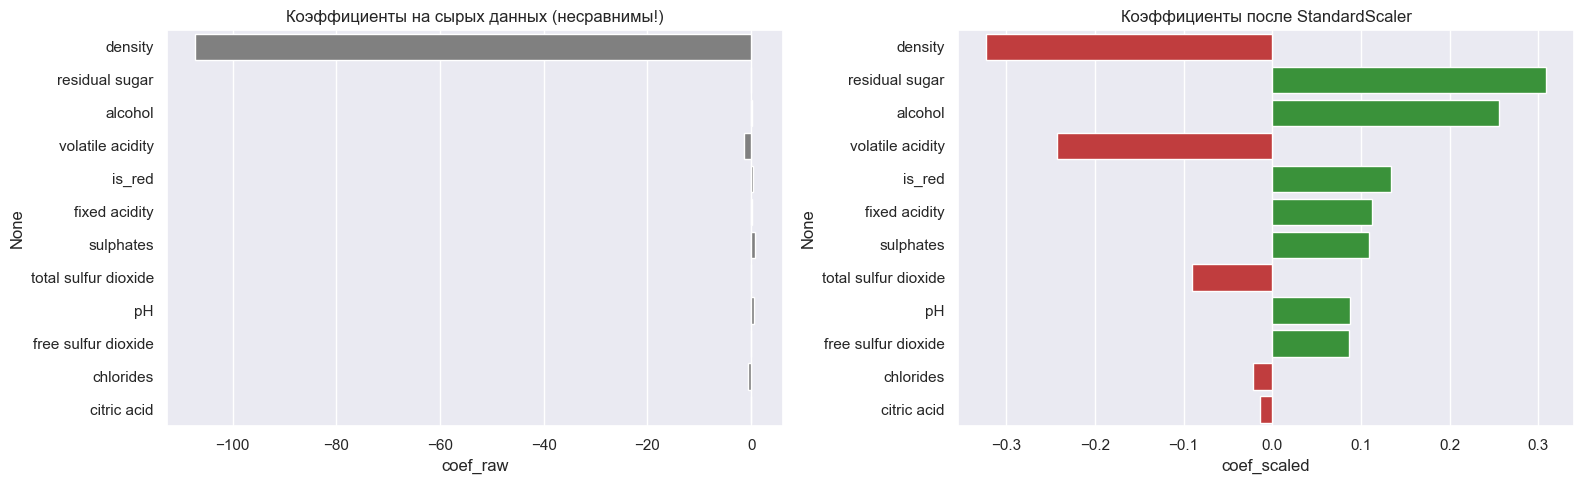

In [14]:
coefs = pd.DataFrame({
    "coef_raw": lr_raw.coef_,
    "feature_std": X_train.std(),
    "coef_scaled": lr.named_steps["regression"].coef_,
}, index=X.columns)
coefs = coefs.reindex(coefs["coef_scaled"].abs().sort_values(ascending=False).index)

fig, axs = plt.subplots(figsize=(16, 5), ncols=2)
sns.barplot(x=coefs["coef_raw"], y=coefs.index, ax=axs[0], color="gray")
axs[0].set_title("Коэффициенты на сырых данных (несравнимы!)")
sns.barplot(x=coefs["coef_scaled"], y=coefs.index, ax=axs[1],
            palette=["tab:red" if c < 0 else "tab:green" for c in coefs["coef_scaled"]])
axs[1].set_title("Коэффициенты после StandardScaler")
plt.tight_layout()
coefs

**Анализ линейной регрессии:**
- RMSE ≈ 0.73 против 0.87 у baseline — модель извлекает полезную информацию, но **не проходит порог 0.70**. RMSE на train и на CV близки к тестовому, значит модель не переобучена, а *недообучена*: зависимость `quality` от признаков нелинейна, и прямая гиперплоскость её не описывает.
- На сырых данных коэффициент `density` огромен (десятки единиц) — не потому, что признак важный, а потому что его разброс ~0.003. Это иллюстрирует, почему сырые коэффициенты сравнивать нельзя.
- После масштабирования наибольшие по модулю коэффициенты: **`density` (−), `residual sugar` (+), `alcohol` (+), `volatile acidity` (−)**.
- `alcohol` и `volatile acidity` ведут себя так, как мы ожидали из EDA. А вот большой **положительный** коэффициент у `residual sugar`, хотя его корреляция с качеством слегка отрицательная, и самый большой по модулю коэффициент у `density` — следствие мультиколлинеарности: `density` почти полностью определяется спиртом и сахаром. Модель «разносит» вклад между связанными признаками: большой минус у плотности компенсируется большим плюсом у сахара. По отдельности такие коэффициенты интерпретировать нельзя, они показывают влияние признака **при фиксированных остальных**, а «изменить плотность, не меняя сахар и спирт» физически невозможно.
- Вывод: коэффициенты линейной модели — это вклад в предсказание *этой* модели, а не «важность в природе»; при коррелированных признаках к ним надо относиться осторожно.

## 5.2. Random Forest Regressor

Случайный лес — ансамбль глубоких решающих деревьев, обученных на бутстреп-выборках и случайных подмножествах признаков; предсказания усредняются. Он умеет моделировать нелинейности и взаимодействия признаков, не требует масштабирования и устойчив к выбросам.

Подберём по кросс-валидации на train долю признаков в каждом разбиении (`max_features`) и минимальный размер листа (`min_samples_leaf`).

In [15]:
rf_search = GridSearchCV(
    RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
    param_grid={"max_features": [0.33, 0.5, 1.0], "min_samples_leaf": [1, 2]},
    cv=cv, scoring="neg_root_mean_squared_error",
)
rf_search.fit(X_train, y_train)

print("Лучшие параметры:", rf_search.best_params_)
print("CV RMSE: %.4f" % -rf_search.best_score_)
pd.DataFrame(rf_search.cv_results_)[["params", "mean_test_score", "std_test_score"]] \
    .assign(mean_test_score=lambda d: -d["mean_test_score"]).sort_values("mean_test_score")

Лучшие параметры: {'max_features': 0.33, 'min_samples_leaf': 1}
CV RMSE: 0.6130


,params,mean_test_score,std_test_score
0,"{'max_features': 0.33, 'min_samples_leaf': 1}",0.613,0.014
2,"{'max_features': 0.5, 'min_samples_leaf': 1}",0.616,0.012
3,"{'max_features': 0.5, 'min_samples_leaf': 2}",0.623,0.011
4,"{'max_features': 1.0, 'min_samples_leaf': 1}",0.624,0.011
1,"{'max_features': 0.33, 'min_samples_leaf': 2}",0.625,0.012
5,"{'max_features': 1.0, 'min_samples_leaf': 2}",0.628,0.011


In [16]:
rf = rf_search.best_estimator_
print("Train RMSE: %.4f" % root_mean_squared_error(y_train, rf.predict(X_train)))
evaluate("Random Forest", y_test, rf.predict(X_test))

Train RMSE: 0.2207
Random Forest: RMSE = 0.5932, MAE = 0.4247


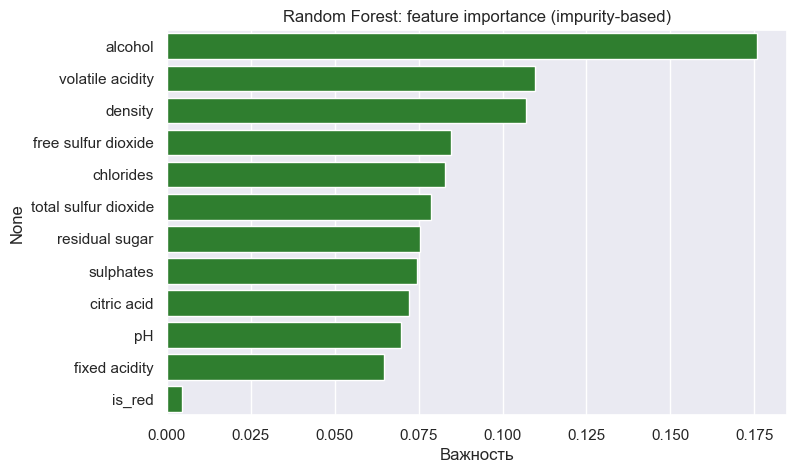

alcohol                 0.176
volatile acidity        0.110
density                 0.107
free sulfur dioxide     0.085
chlorides               0.083
total sulfur dioxide    0.079
residual sugar          0.076
sulphates               0.075
citric acid             0.072
pH                      0.070
fixed acidity           0.065
is_red                  0.005
dtype: float64

In [17]:
rf_importance = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)

plt.figure(figsize=(8, 5))
sns.barplot(x=rf_importance.values, y=rf_importance.index, color="forestgreen")
plt.title("Random Forest: feature importance (impurity-based)")
plt.xlabel("Важность")
plt.show()
rf_importance

**Анализ Random Forest:**
- RMSE ≈ 0.59 — существенно лучше линейной регрессии и baseline, **порог 0.70 пройден с запасом**.
- Train RMSE очень маленький (~0.22): глубокие деревья почти запоминают обучающую выборку, но усреднение 300 деревьев гасит дисперсию, поэтому на тесте качество всё равно лучшее. Лучшим оказался `max_features=0.33` — более «декоррелированные» деревья дают более сильный ансамбль.
- **Самые важные признаки:** `alcohol` (с большим отрывом), затем `volatile acidity` и `density`. Это ровно те признаки, которые выделились в EDA по корреляции, — результаты согласуются.
- Отличие от линейной регрессии: `residual sugar` у леса — середняк, а не один из лидеров; огромный линейный коэффициент у него был артефактом мультиколлинеарности с `density`. При этом признаки с почти нулевой корреляцией (`free sulfur dioxide`, `chlorides`, `total sulfur dioxide`) получают заметную важность: лес находит в них нелинейную зависимость. Например, у `free sulfur dioxide` есть «оптимальный диапазон» — слишком мало и слишком много одинаково плохо, а коэффициент корреляции такое не улавливает.
- `is_red` почти не используется: как мы видели в EDA, тип вина и так восстанавливается по химическим признакам.
- Важно: impurity-based importance смещена в пользу непрерывных признаков с большим числом уникальных значений, а важность коррелированных признаков (`alcohol`/`density`) делится между ними. Поэтому дальше дополнительно посчитаем permutation importance.

## 5.3. Gradient Boosting Regressor

Градиентный бустинг строит деревья **последовательно**: каждое новое неглубокое дерево исправляет ошибки (антиградиент функции потерь) текущего ансамбля. Подберём по CV число деревьев и их глубину при фиксированном `learning_rate=0.05`; `subsample=0.8` добавляет стохастичности и регуляризации.

In [18]:
gb_search = GridSearchCV(
    GradientBoostingRegressor(learning_rate=0.05, subsample=0.8, random_state=RANDOM_STATE),
    param_grid={"n_estimators": [300, 600], "max_depth": [3, 5]},
    cv=cv, scoring="neg_root_mean_squared_error", n_jobs=-1,
)
gb_search.fit(X_train, y_train)

print("Лучшие параметры:", gb_search.best_params_)
print("CV RMSE: %.4f" % -gb_search.best_score_)
pd.DataFrame(gb_search.cv_results_)[["params", "mean_test_score", "std_test_score"]] \
    .assign(mean_test_score=lambda d: -d["mean_test_score"]).sort_values("mean_test_score")

Лучшие параметры: {'max_depth': 5, 'n_estimators': 600}
CV RMSE: 0.6398


,params,mean_test_score,std_test_score
3,"{'max_depth': 5, 'n_estimators': 600}",0.640,0.014
2,"{'max_depth': 5, 'n_estimators': 300}",0.651,0.012
1,"{'max_depth': 3, 'n_estimators': 600}",0.671,0.011
0,"{'max_depth': 3, 'n_estimators': 300}",0.680,0.011


In [19]:
gb = gb_search.best_estimator_
print("Train RMSE: %.4f" % root_mean_squared_error(y_train, gb.predict(X_train)))
evaluate("Gradient Boosting", y_test, gb.predict(X_test))

Train RMSE: 0.3319
Gradient Boosting: RMSE = 0.6219, MAE = 0.4654


,Random Forest,Gradient Boosting,rank_RF,rank_GB
alcohol,0.176,0.249,1,1
volatile acidity,0.110,0.131,2,2
density,0.107,0.070,3,7
free sulfur dioxide,0.085,0.089,4,3
chlorides,0.083,0.058,5,9
total sulfur dioxide,0.079,0.075,6,5
residual sugar,0.076,0.082,7,4
sulphates,0.075,0.075,8,6
citric acid,0.072,0.053,9,11
pH,0.070,0.061,10,8


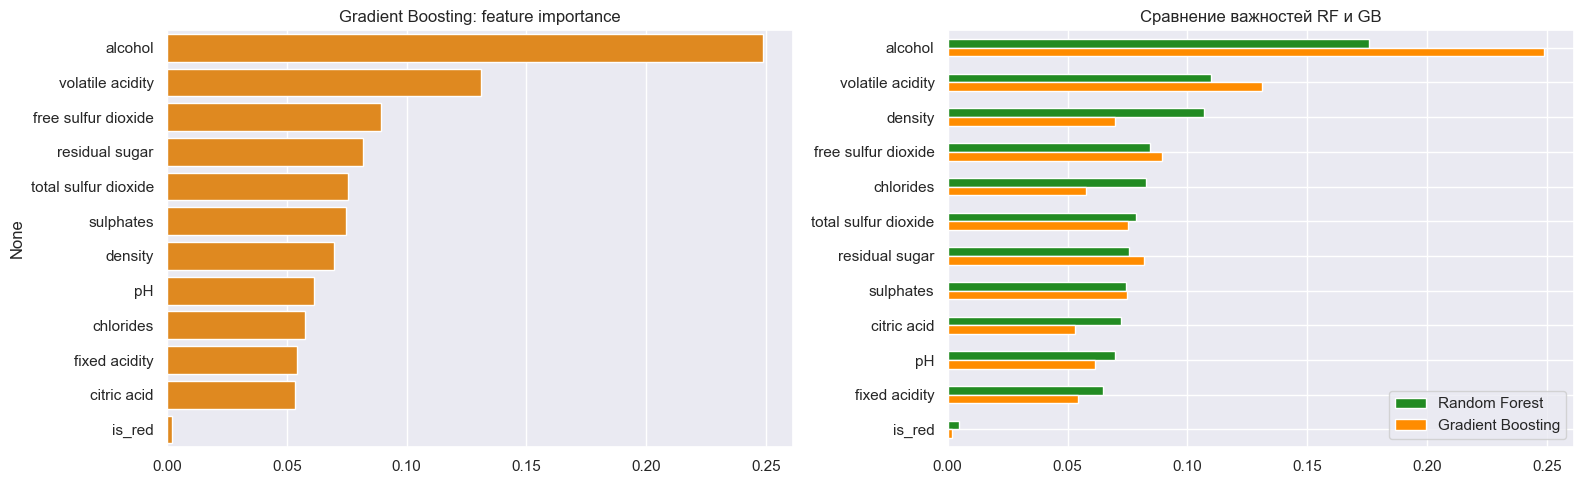

In [20]:
gb_importance = pd.Series(gb.feature_importances_, index=X.columns).sort_values(ascending=False)

fig, axs = plt.subplots(figsize=(16, 5), ncols=2)
sns.barplot(x=gb_importance.values, y=gb_importance.index, ax=axs[0], color="darkorange")
axs[0].set_title("Gradient Boosting: feature importance")

imp_cmp = pd.DataFrame({"Random Forest": rf_importance, "Gradient Boosting": gb_importance})
imp_cmp = imp_cmp.sort_values("Random Forest", ascending=False)
imp_cmp.plot.barh(ax=axs[1], color=["forestgreen", "darkorange"])
axs[1].invert_yaxis()
axs[1].set_title("Сравнение важностей RF и GB")
plt.tight_layout()

imp_cmp.assign(rank_RF=imp_cmp["Random Forest"].rank(ascending=False).astype(int),
               rank_GB=imp_cmp["Gradient Boosting"].rank(ascending=False).astype(int))

**Анализ Gradient Boosting:**
- RMSE ≈ 0.62: лучше линейной регрессии и baseline, порог 0.70 пройден, но немного уступает случайному лесу.
- **Сравнение важностей RF и GB:** лидеры совпадают — **`alcohol` на первом месте и `volatile acidity` на втором**. Бустинг ещё сильнее концентрирует важность на `alcohol` (~0.25 против ~0.18 у леса), а `density` у него опускается заметно ниже. Это объяснимо: бустинг жадно выбирает лучший признак для разбиения, и из пары сильно коррелированных `alcohol`/`density` почти всегда берёт `alcohol`. В лесу же из-за `max_features=0.33` во многих разбиениях `alcohol` недоступен, и его «заменяет» `density` — важность размазывается между дублирующими друг друга признаками.
- Хвост списка у обеих моделей одинаковый: `is_red`, `citric acid`, `fixed acidity`, `pH` — малоинформативные признаки.

# 6. Честное сравнение моделей

Все модели обучены на одном и том же `X_train`, гиперпараметры выбраны по одной и той же кросс-валидации на train, и все оценены на одном и том же `X_test`.

In [21]:
results_df = pd.DataFrame(results).T
results_df["RMSE / MAE"] = results_df["RMSE"] / results_df["MAE"]
results_df["Улучшение RMSE vs baseline"] = (1 - results_df["RMSE"] / results_df.loc["Baseline", "RMSE"]).map("{:.1%}".format)
results_df["RMSE < 0.70"] = results_df["RMSE"] < 0.70
results_df

,RMSE,MAE,RMSE / MAE,Улучшение RMSE vs baseline,RMSE < 0.70
Baseline,0.874,0.686,1.274,0.0%,False
Linear Regression,0.728,0.568,1.282,16.7%,False
Random Forest,0.593,0.425,1.397,32.1%,True
Gradient Boosting,0.622,0.465,1.336,28.8%,True


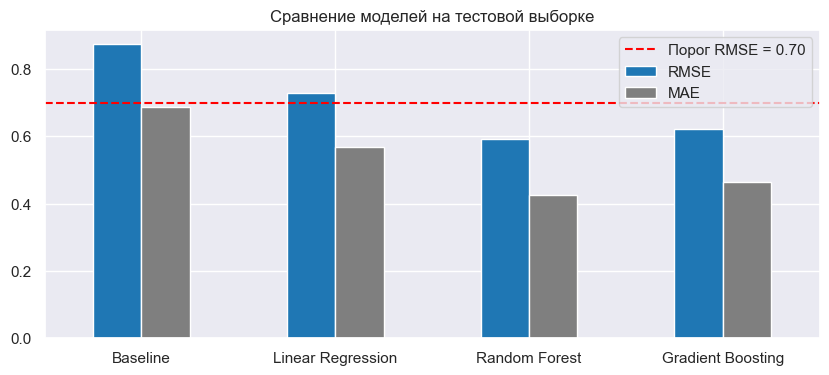

In [22]:
fig, ax = plt.subplots(figsize=(10, 4))
results_df[["RMSE", "MAE"]].plot.bar(ax=ax, rot=0, color=["tab:blue", "tab:gray"])
ax.axhline(0.70, color="red", ls="--", label="Порог RMSE = 0.70")
ax.set_title("Сравнение моделей на тестовой выборке")
ax.legend()
plt.show()

**Выводы по сравнению:**
- **Baseline превзошли все три модели**: каждая извлекает из признаков реальную информацию.
- **Порог RMSE < 0.70 проходят только ансамбли деревьев**; линейная регрессия (≈ 0.73) — нет.
- **Linear Regression хуже всех моделей.** Причина — в особенностях данных: зависимость качества от химии нелинейна (оптимальные диапазоны у `free sulfur dioxide`, `pH`, `sulphates`; эффект сахара разный для красных и белых), есть выбросы и тяжёлые хвосты, а сильная мультиколлинеарность делает модель неустойчивой. Ошибки на train и test почти равны — это недообучение (высокое смещение), и бóльшая сложность модели здесь объективно нужна.
- **Деревья решают эти проблемы:** им не важны масштабы и монотонные преобразования признаков, они нечувствительны к выбросам, автоматически ловят пороговые эффекты и взаимодействия (например, «высокий спирт **и** низкая летучая кислотность»).
- **Random Forest оказался лучше Gradient Boosting.** Возможные причины:
  1. Таргет очень шумный (субъективные экспертные оценки), а соседние классы сильно перекрываются. Лес снижает в первую очередь *дисперсию* за счёт усреднения многих независимых глубоких деревьев и хорошо работает в шумных задачах. Бустинг же последовательно подгоняется под остатки, в том числе под шум, и ему нужна более тонкая настройка (меньший `learning_rate`, больше деревьев, регуляризация).
  2. Глубокие деревья леса почти запоминают обучающие объекты, а в данных много дубликатов и почти одинаковых вин (одни и те же партии). Если такой «двойник» есть в train, лес даст для тестового объекта почти точный ответ. Это частично объясняет и большую разницу между train RMSE (~0.22) и test RMSE у леса.
  3. Сетка параметров для бустинга была небольшой — при более тщательном подборе разрыв, вероятно, сократится.
- **RMSE/MAE ≈ 1.28–1.40** у всех моделей: ошибки распределены неравномерно — большинство мелкие, но есть редкие крупные промахи. У ансамблей деревьев отношение выше: они часто угадывают почти точно (MAE мала), но на «нетипичных» винах ошибаются сильно. Это подробнее разберём в анализе ошибок.
- **Лучшая модель — Random Forest** (выбор подтверждается и кросс-валидацией на train, а не только тестом).

# 7. Feature importance

Сравним три способа оценки важности:
1. **|коэффициенты|** стандартизированной линейной регрессии;
2. **impurity-based importance** RF и GB (уже посчитаны выше);
3. **permutation importance** — насколько вырастает RMSE модели, если случайно перемешать значения признака. Этот метод не зависит от устройства модели и не смещён в пользу признаков с большим числом уникальных значений.

Permutation importance считаем на тестовой выборке — это **анализ уже выбранных и зафиксированных моделей**, никакие решения по нему не принимаются. Все важности нормируем на сумму, чтобы сравнивать их на одной шкале.

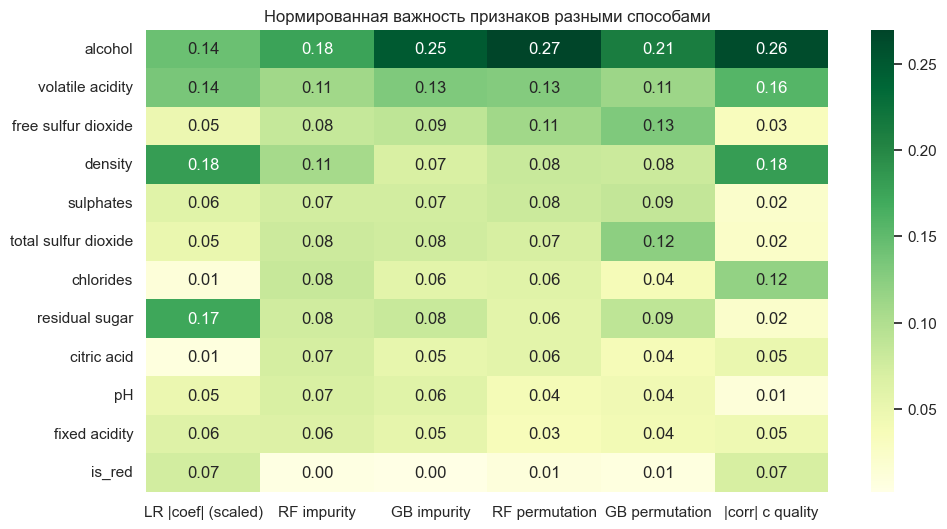

,rank: LR |coef| (scaled),rank: RF impurity,rank: GB impurity,rank: RF permutation,rank: GB permutation,rank: |corr| с quality
alcohol,3,1,1,1,1,1
volatile acidity,4,2,2,2,4,3
free sulfur dioxide,10,4,3,3,2,8
density,1,3,7,4,7,2
sulphates,7,8,6,5,6,10
total sulfur dioxide,8,6,5,6,3,9
chlorides,11,5,9,7,11,4
residual sugar,2,7,4,8,5,11
citric acid,12,9,11,9,10,6
pH,9,10,8,10,8,12


In [23]:
def perm_imp(model):
    r = permutation_importance(model, X_test, y_test, n_repeats=10, random_state=RANDOM_STATE,
                               scoring="neg_root_mean_squared_error", n_jobs=-1)
    return pd.Series(r.importances_mean, index=X.columns)

perm_rf = perm_imp(rf)
perm_gb = perm_imp(gb)

norm = lambda s: s.clip(lower=0) / s.clip(lower=0).sum()
all_imp = pd.DataFrame({
    "LR |coef| (scaled)": norm(coefs["coef_scaled"].abs()),
    "RF impurity": norm(rf_importance),
    "GB impurity": norm(gb_importance),
    "RF permutation": norm(perm_rf),
    "GB permutation": norm(perm_gb),
    "|corr| с quality": norm(quality_corr.abs()),
}).sort_values("RF permutation", ascending=False)

plt.figure(figsize=(11, 6))
sns.heatmap(all_imp, annot=True, fmt=".2f", cmap="YlGn")
plt.title("Нормированная важность признаков разными способами")
plt.show()

all_imp.rank(ascending=False).astype(int).add_prefix("rank: ")

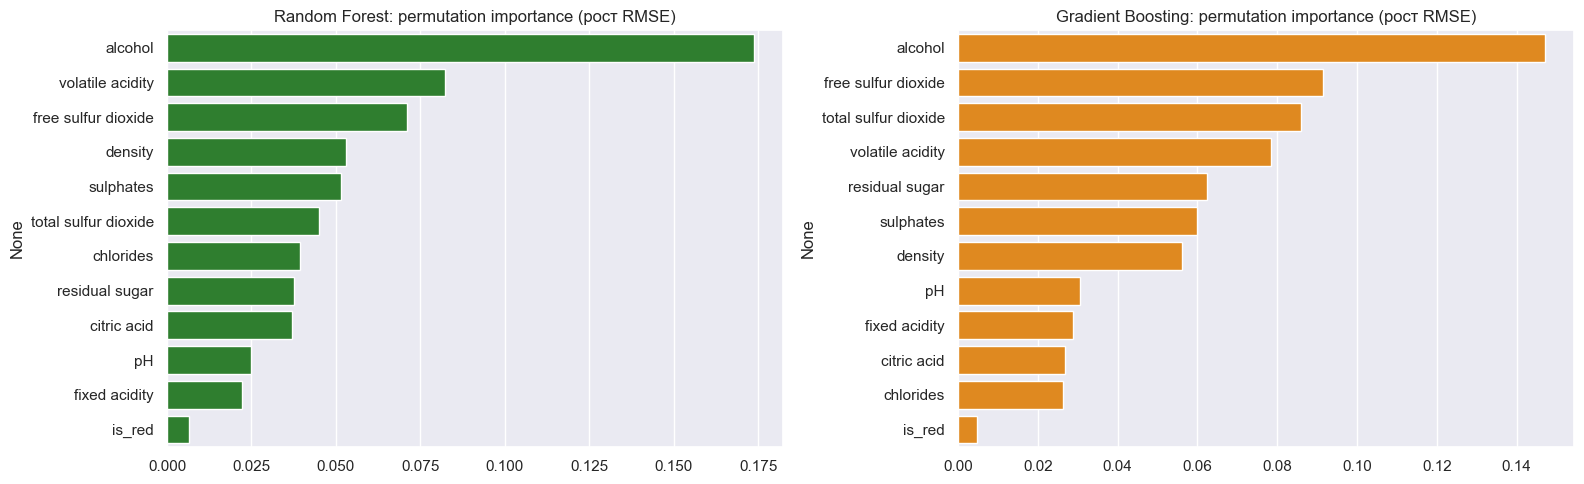

In [24]:
fig, axs = plt.subplots(figsize=(16, 5), ncols=2)
for ax, (name, s), color in zip(axs, [("Random Forest", perm_rf), ("Gradient Boosting", perm_gb)],
                                ["forestgreen", "darkorange"]):
    s = s.sort_values(ascending=False)
    sns.barplot(x=s.values, y=s.index, ax=ax, color=color)
    ax.set_title(f"{name}: permutation importance (рост RMSE)")
plt.tight_layout()

**Выводы по важности признаков:**
- **Наиболее важные признаки:** `alcohol` — бесспорный лидер у всех методов и у корреляционного анализа. Стабильно в топ-3 также **`volatile acidity`**. Дальше — `free sulfur dioxide` и `density` / `residual sugar` (в зависимости от метода).
- **Согласие с EDA:** два лидера EDA по корреляции (`alcohol`, `volatile acidity`) — лидеры и у моделей. Расхождения тоже информативны:
  - `density` в EDA второй по корреляции, но у моделей он опускается ниже (4-е место в permutation importance леса, 7-е в impurity-важности бустинга): информация о плотности в основном *дублирует* спирт и сахар, и при перемешивании `density` модель берёт её из `alcohol`;
  - `free sulfur dioxide` почти не коррелирует с качеством линейно, но стабильно в топе у деревьев — классический признак нелинейной зависимости;
  - `is_red`, `citric acid`, `fixed acidity` неважны всеми методами.
- **Сравнение RF и GB:** топ-2 совпадает; GB сильнее концентрируется на `alcohol` и меньше на `density` (жадный выбор одного из коррелированных признаков), RF распределяет важность ровнее.
- **Линейная регрессия** выделяется: у неё в лидерах `density` и `residual sugar` — как обсуждалось, из-за мультиколлинеарности (большие компенсирующие друг друга коэффициенты).

**Можно ли по feature importance утверждать, что изменение признака является *причиной* изменения качества вина?**

**Нет.** Feature importance показывает, насколько признак полезен *данной модели* для предсказания на *данных наблюдениях*, — это мера ассоциации, а не причинности:
1. **Данные наблюдательные, а не экспериментальные.** Никто не менял содержание спирта в одном и том же вине при прочих равных. Высокий спирт может быть следствием общих причин — более зрелого винограда, лучшего года, технологии виноделия, — которые одновременно улучшают и другие свойства вина (вкус, аромат), не попавшие в данные. Это конфаундеры.
2. **Коррелированные признаки делят и подменяют важность.** `alcohol` и `density` взаимозаменяемы для модели; разные модели и методы по-разному распределяют между ними важность. Важность одного признака может «принадлежать» другому, с ним связанному.
3. **Важность зависит от модели и метода** (мы видели разные ранжирования у LR, RF, GB, impurity и permutation), а причинная связь не может зависеть от того, каким алгоритмом мы её измеряем.
4. **Неважность тоже не означает отсутствие влияния:** признак может влиять на качество, но его эффект уже «покрыт» другими признаками или в данных он мало варьируется.

Поэтому корректная формулировка: «содержание спирта — самый информативный предиктор экспертной оценки в этом датасете». Утверждать, что «добавление спирта улучшит вино», можно было бы только по результатам контролируемого эксперимента.

# 8. Анализ ошибок лучшей модели (Random Forest)

count    1300.000
mean        0.425
std         0.414
min         0.000
50%         0.297
75%         0.587
90%         0.993
95%         1.240
99%         1.871
max         2.643
Name: abs_error, dtype: float64
Доля ошибок < 0.5 балла: 68.5%
Доля ошибок > 1 балла:  9.9%


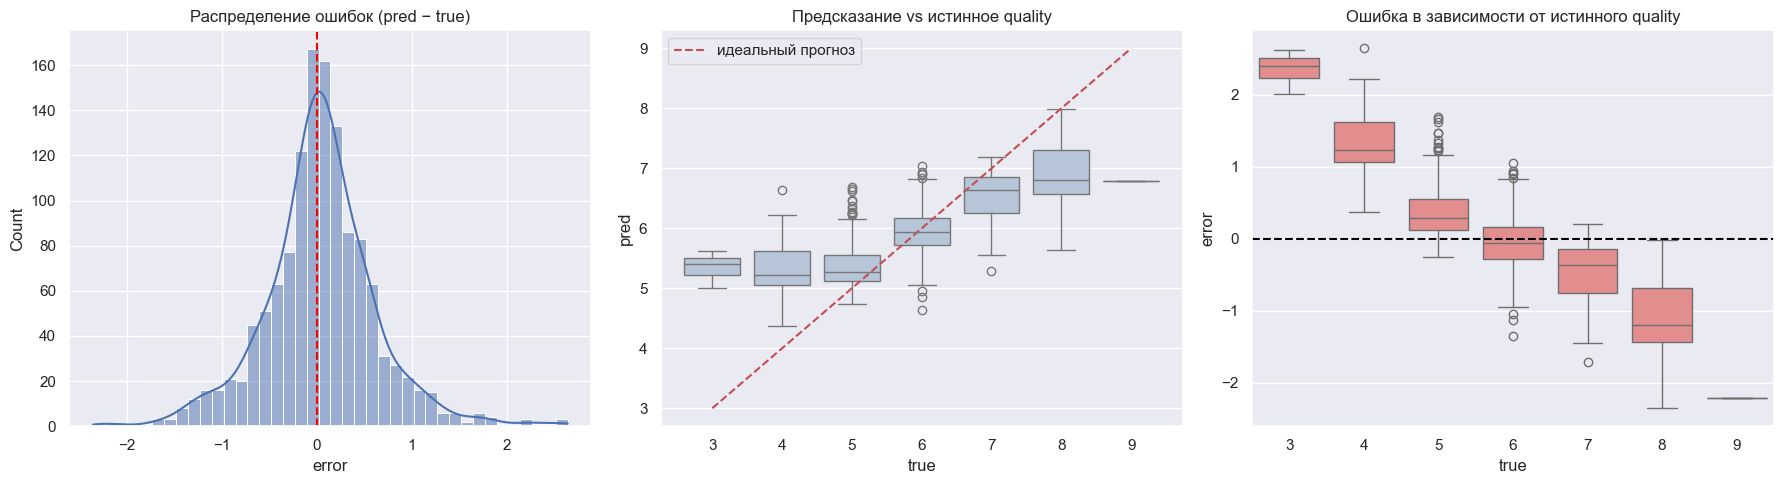

In [25]:
best_model = rf
y_pred = best_model.predict(X_test)

errors = pd.DataFrame({"true": y_test, "pred": y_pred}, index=y_test.index)
errors["error"] = errors["pred"] - errors["true"]
errors["abs_error"] = errors["error"].abs()

fig, axs = plt.subplots(figsize=(18, 5), ncols=3)
sns.histplot(errors["error"], bins=40, kde=True, ax=axs[0])
axs[0].axvline(0, color="red", ls="--")
axs[0].set_title("Распределение ошибок (pred − true)")

sns.boxplot(data=errors, x="true", y="pred", ax=axs[1], color="lightsteelblue")
lims = sorted(errors["true"].unique())
axs[1].plot(range(len(lims)), lims, "r--", label="идеальный прогноз")
axs[1].set_title("Предсказание vs истинное quality")
axs[1].legend()

sns.boxplot(data=errors, x="true", y="error", ax=axs[2], color="lightcoral")
axs[2].axhline(0, color="black", ls="--")
axs[2].set_title("Ошибка в зависимости от истинного quality")
plt.tight_layout()

print(errors["abs_error"].describe(percentiles=[0.5, 0.75, 0.9, 0.95, 0.99]).round(3))
print("Доля ошибок < 0.5 балла: %.1f%%" % (100 * (errors["abs_error"] < 0.5).mean()))
print("Доля ошибок > 1 балла:  %.1f%%" % (100 * (errors["abs_error"] > 1).mean()))

In [26]:
by_quality = errors.groupby("true").apply(lambda g: pd.Series({
    "n_test": len(g),
    "n_train": (y_train == g.name).sum(),
    "mean_pred": g["pred"].mean(),
    "bias (mean error)": g["error"].mean(),
    "MAE": g["abs_error"].mean(),
    "RMSE": np.sqrt((g["error"] ** 2).mean()),
}))
by_quality

,n_test,n_train,mean_pred,bias (mean error),MAE,RMSE
true,,,,,,
3,6.0,24.0,5.358,2.358,2.358,2.368
4,43.0,173.0,5.313,1.313,1.313,1.390
5,428.0,1710.0,5.377,0.377,0.387,0.506
6,567.0,2269.0,5.942,-0.058,0.293,0.379
7,216.0,863.0,6.518,-0.482,0.486,0.629
8,39.0,154.0,6.907,-1.093,1.093,1.234
9,1.0,4.0,6.790,-2.210,2.210,2.210


**Работает ли модель одинаково хорошо для разных значений `quality`?** Нет.
- Распределение ошибок центрировано около нуля и симметрично, большинство ошибок меньше 0.5 балла, но есть хвост из крупных промахов (1–3 балла), которые и раздувают RMSE относительно MAE.
- Для самых частых классов **5 и 6** ошибки минимальны и смещение почти нулевое.
- Для **крайних значений** видна систематическая ошибка — **регрессия к среднему**: вина с оценкой 3–4 модель переоценивает (bias > 0), а вина с 8–9 — недооценивает (bias < 0). Средний прогноз для «тройки» и «девятки» оказывается где-то в районе 5–7, и RMSE для них в несколько раз выше, чем для 5–6.

**Почему модель хуже предсказывает редкие значения `quality`:**
1. **Мало обучающих примеров:** в train всего 24 вина с оценкой 3 и 4 — с оценкой 9. Модель почти не видела, как они выглядят, и не может выучить их признаки.
2. **Устройство модели:** лист дерева и ансамбль *усредняют* таргеты похожих объектов. Около необычного вина почти всегда окажутся «соседи» с типичными оценками 5–6, и среднее сместится к центру. Предсказание случайного леса в принципе не может выйти за пределы диапазона обучающих таргетов и редко приближается к его краям.
3. **Функция потерь:** MSE-оптимальная модель при неопределённости выдаёт условное среднее; для редкого класса «рискованное» крайнее предсказание в среднем дороже, чем осторожное центральное.
4. **Шум в разметке:** оценка — медиана мнений нескольких экспертов; граница между «очень хорошим» и «просто хорошим» вином субъективна, а химические признаки не описывают аромат, вкус, сорт винограда и т.п.

In [27]:
top_errors = errors.sort_values("abs_error", ascending=False).head(10)
top_errors_full = top_errors.join(X_test)
top_errors_full

,true,pred,error,abs_error,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,is_red
6107,4,6.643,2.643,2.643,5.8,0.260,0.30,2.60,0.034,75.0,129.0,0.990,3.20,0.38,11.5,0
2339,3,5.620,2.620,2.620,6.9,0.390,0.40,4.60,0.022,5.0,19.0,0.992,3.31,0.37,12.6,0
1850,3,5.520,2.520,2.520,8.5,0.260,0.21,16.20,0.074,41.0,197.0,0.998,3.02,0.50,9.8,0
3287,3,5.490,2.490,2.490,6.7,0.250,0.26,1.55,0.041,118.5,216.0,0.995,3.55,0.63,9.4,0
3005,8,5.643,-2.357,2.357,8.2,0.220,0.36,6.80,0.034,12.0,90.0,0.994,3.01,0.38,10.5,0
1374,3,5.310,2.310,2.310,6.8,0.815,0.00,1.20,0.267,16.0,29.0,0.995,3.32,0.51,9.8,1
5369,4,6.220,2.220,2.220,7.4,0.270,0.31,2.40,0.014,15.0,143.0,0.991,3.03,0.65,12.0,0
3715,4,6.213,2.213,2.213,6.8,0.200,0.27,1.20,0.034,19.0,68.0,0.990,3.14,0.37,11.7,0
2426,9,6.790,-2.210,2.210,7.4,0.240,0.36,2.00,0.031,27.0,139.0,0.991,3.28,0.48,12.5,0
1469,3,5.203,2.203,2.203,7.3,0.980,0.05,2.10,0.061,20.0,49.0,0.997,3.31,0.55,9.7,1


In [28]:
# сравним самые крупные ошибки с типичными винами того же истинного качества и того качества, которое предсказала модель
key_features = ["alcohol", "volatile acidity", "density", "free sulfur dioxide", "residual sugar", "sulphates", "chlorides", "is_red"]
train_full = X_train.assign(quality=y_train)
medians_by_q = train_full.groupby("quality")[key_features].median()

for idx, row in top_errors_full.head(4).iterrows():
    true_q, pred_q = int(row["true"]), int(round(row["pred"]))
    cmp = pd.DataFrame({
        "это вино": row[key_features],
        f"медиана train, quality={true_q} (истина)": medians_by_q.loc[true_q],
        f"медиана train, quality={pred_q} (прогноз)": medians_by_q.loc[pred_q],
    })
    print(f"\nОбъект {idx}: true = {true_q}, pred = {row['pred']:.2f}")
    display(cmp.T.round(3))


Объект 6107: true = 4, pred = 6.64


,alcohol,volatile acidity,density,free sulfur dioxide,residual sugar,sulphates,chlorides,is_red
это вино,11.5,0.26,0.990,75.0,2.6,0.38,0.034,0.0
"медиана train, quality=4 (истина)",10.0,0.38,0.995,16.0,2.3,0.49,0.051,0.0
"медиана train, quality=7 (прогноз)",11.4,0.27,0.992,29.0,2.7,0.52,0.039,0.0



Объект 2339: true = 3, pred = 5.62


,alcohol,volatile acidity,density,free sulfur dioxide,residual sugar,sulphates,chlorides,is_red
это вино,12.60,0.39,0.992,5.0,4.60,0.370,0.022,0.0
"медиана train, quality=3 (истина)",10.45,0.46,0.996,17.0,3.15,0.505,0.054,0.0
"медиана train, quality=6 (прогноз)",10.50,0.27,0.995,30.0,3.20,0.520,0.046,0.0



Объект 1850: true = 3, pred = 5.52


,alcohol,volatile acidity,density,free sulfur dioxide,residual sugar,sulphates,chlorides,is_red
это вино,9.80,0.26,0.998,41.0,16.20,0.500,0.074,0.0
"медиана train, quality=3 (истина)",10.45,0.46,0.996,17.0,3.15,0.505,0.054,0.0
"медиана train, quality=6 (прогноз)",10.50,0.27,0.995,30.0,3.20,0.520,0.046,0.0



Объект 3287: true = 3, pred = 5.49


,alcohol,volatile acidity,density,free sulfur dioxide,residual sugar,sulphates,chlorides,is_red
это вино,9.40,0.25,0.995,118.5,1.55,0.630,0.041,0.0
"медиана train, quality=3 (истина)",10.45,0.46,0.996,17.0,3.15,0.505,0.054,0.0
"медиана train, quality=5 (прогноз)",9.60,0.33,0.996,27.0,3.00,0.500,0.053,0.0


**Объяснение крупных ошибок.** Среди объектов с максимальной ошибкой преобладают вина с крайними оценками (3–4 и 8), реже — «обычные» вина с нетипичной химией. Сравнение с медианными профилями показывает общую картину:
- **Низкокачественные вина, которые модель переоценила.** По ключевым признакам (`alcohol`, `volatile acidity`, `density`) такие вина часто выглядят как типичные вина на 5–6 или даже лучше. Признаки, по которым эксперт поставил низкую оценку (дефекты аромата, окисление, посторонние привкусы), в датасете просто отсутствуют — по химии модель не может их увидеть.
- **Высокие оценки, которые модель недооценила.** Например, вина с умеренным спиртом, но высокой оценкой: модель опирается в первую очередь на `alcohol`, и вино «без признаков хорошего вина» получает центральный прогноз. Его качество определяется чем-то, что не измерено (сорт винограда, выдержка, баланс вкуса).
- **Нетипичные значения признаков.** У части объектов есть выбросы (очень высокий `free sulfur dioxide`, `chlorides` или `residual sugar`) — в таких областях пространства признаков мало обучающих точек, и прогноз ненадёжен.
- **Возможный шум разметки:** при наличии дубликатов с одинаковой химией и разными оценками ошибка неизбежна для любой модели.

**Разбор конкретных объектов** (индексы из таблицы выше; так как разбиение зафиксировано `random_state`, они воспроизводятся):
- **Объект 6107** (истина 4, прогноз ≈ 6.6): белое вино с `alcohol` = 11.5 и низкой `volatile acidity` = 0.26 — по двум главным признакам это профиль вина на 7 (сравните с медианами в таблице). Единственная аномалия — очень высокий `free sulfur dioxide` = 75 (медиана для «четвёрок» — 16). Вероятно, низкую оценку вызвал резкий сернистый запах или другой дефект, который модель по химии не связывает с низким качеством: таких примеров в train почти нет.
- **Объект 2339** (истина 3, прогноз ≈ 5.6): высокий спирт 12.6% тянет прогноз вверх, но `free sulfur dioxide` всего 5 — вино практически не защищено от окисления, и, скорее всего, именно окисленность привела к оценке 3. Сочетание «высокий спирт + почти нет SO₂» слишком редкое, чтобы модель его выучила.
- **Объект 3287** (истина 3, прогноз ≈ 5.5): экстремальный `free sulfur dioxide` = 118.5 — далеко за пределами типичных значений. В этой области пространства признаков почти нет обучающих точек, и лес выдаёт усреднённый прогноз «как у обычного вина на 5».
- **Объект 3005** (истина 8, прогноз ≈ 5.6) и **объект 2426** (истина 9 — одно из всего 5 вин с такой оценкой, прогноз ≈ 6.8): «скромные» по химии вина, высокие оценки которых объясняются тем, чего нет в данных (аромат, сорт, выдержка). Для оценки 9 в train всего 4 примера — модель физически не может научиться её предсказывать.
- **Объект 1374** (красное, истина 3, прогноз ≈ 5.3): здесь модель «видит» проблему — очень высокие `volatile acidity` = 0.815 и `chlorides` = 0.267 — и снижает прогноз, но из-за усреднения по соседям с оценками 5–6 не может опустить его до 3.

Общий вывод: все 10 крупнейших ошибок — вина с редкими оценками (3, 4, 8, 9), и все они ошибаются **в сторону центра**. Это подтверждает таблицу смещений по классам: для оценки 3 средняя ошибка +2.36, для 8 — −1.09, а для 6 — лишь −0.06.

**Как можно было бы улучшить:** подобрать гиперпараметры тщательнее (особенно у бустинга), попробовать бустинговые библиотеки (LightGBM/CatBoost), объединить модели в ансамбль, рассмотреть постановку задачи как порядковой классификации или использовать веса для редких классов, если важно лучше предсказывать крайние оценки.

# Итоги

1. **EDA:** 6497 вин, 12 признаков, пропусков нет. Таргет сильно несбалансирован (77% — оценки 5–6). Сильнейшая связь с качеством у `alcohol` (+), затем `density` (−, дублирует спирт), `volatile acidity` (−), `chlorides` (−). Много мультиколлинеарности и нелинейных зависимостей.
2. **Разбиение:** 80/20, стратификация по `quality`, `random_state=42`; все решения — по 5-fold CV на train, тест использован только для финальной оценки.
3. **Baseline** (среднее train): RMSE ≈ 0.87.
4. **Linear Regression:** RMSE ≈ 0.73 — лучше baseline, но не проходит порог: модель недообучена из-за нелинейности зависимостей.
5. **Random Forest:** RMSE ≈ 0.59 — **лучшая модель**, порог 0.70 пройден. **Gradient Boosting:** RMSE ≈ 0.62, тоже проходит порог.
6. **Важные признаки:** `alcohol` и `volatile acidity` — во всех методах; деревья дополнительно находят нелинейный сигнал в `free sulfur dioxide`. Feature importance отражает предсказательную полезность, а не причинность.
7. **Ошибки:** модель хорошо предсказывает частые оценки 5–6 и систематически стягивает к центру редкие крайние оценки (3–4, 8–9) из-за нехватки примеров, усредняющей природы модели и неполноты признаков.

In [29]:
results_df[["RMSE", "MAE"]].round(4)

,RMSE,MAE
Baseline,0.874,0.686
Linear Regression,0.728,0.568
Random Forest,0.593,0.425
Gradient Boosting,0.622,0.465
